In [71]:
"""
Karlsruhe Digitalstrategie Knowledge Graph Visualization
========================================================
Analyzing governance documents, timelines, and relationships
"""

import json
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from collections import defaultdict

# ============================================
# 1. Load and Parse JSON Data
# ============================================

with open('search_results_20260812_160529.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

print(f"Loaded data with {len(data)} top-level keys")
print(f"Total files: {data['stats']['total_files']}")
print(f"Total events: {data['stats']['total_events']}")

Loaded data with 5 top-level keys
Total files: 6
Total events: 12


In [72]:
# ============================================
# SECTION 2: Initialize Graph & Start Adding Nodes
# ============================================

# Initialize graph
G = nx.DiGraph()
G.graph['name'] = 'Karlsruhe Digital Governance'

# Node tracking for deduplication
nodes_added = set()

# --- CATEGORY NODES GO HERE (FIXED VERSION) ---
# ↓↓↓↓ ADD THIS CODE BLOCK RIGHT AFTER nodes_added initialization ↓↓↓↓
for event_type, count in data['stats']['event_types'].items():
    # FIXED: Ensure all attributes are set for category nodes
    G.add_node(
        ('category', event_type),
        node_type='category',             # REQUIRED attribute
        name=f'{event_type} Documents',   # REQUIRED for labeling
        count=count,                      # Extra data
        color='gold',                     # For visualization
        size=600                          # For visualization
    )
    nodes_added.add(('category', event_type))
# ↑↑↑↑ END OF CATEGORY NODE BLOCK ↑↑↑↑

In [73]:
# ============================================
# SECTION 2b: Add Paper Nodes
# ============================================

paper_nodes = []
for event in data.get('timeline', []):
    for e in event.get('events', []):
        if e['type'] == 'Paper':
            details = e.get('details', {})
            paper_id = details.get('oparlKey') or details.get('id')
            if paper_id and ('Paper', paper_id) not in nodes_added:
                G.add_node(
                    ('Paper', paper_id),
                    node_type='Paper',      # REQUIRED attribute
                    name=details.get('name', 'Unknown'),
                    reference=details.get('reference', ''),
                    paper_type=details.get('paperType', ''),
                    date=e.get('date', ''),
                    color='blue',
                    size=400
                )
                nodes_added.add(('Paper', paper_id))
                paper_nodes.append(details)

In [74]:
# ============================================
# SECTION 2c: Add File Nodes
# ============================================

file_nodes = []
for event in data.get('timeline', []):
    for e in event.get('events', []):
        if e['type'] == 'AuxFile':
            details = e.get('details', {})
            file_oparl_key = details.get('oparlKey')
            if file_oparl_key and ('File', file_oparl_key) not in nodes_added:
                G.add_node(
                    ('File', file_oparl_key),
                    node_type='File',       # REQUIRED attribute
                    name=details.get('name', 'Unknown'),
                    file_name=details.get('fileName', ''),
                    date=e.get('date', ''),
                    color='green',
                    size=350
                )
                nodes_added.add(('File', file_oparl_key))
                file_nodes.append(details)

In [75]:
# ============================================
# SECTION 2d: Add Body Nodes
# ============================================

body_nodes = set()
for paper in paper_nodes:
    body_sid = paper.get('bodySid')
    if body_sid and body_sid not in body_nodes:
        G.add_node(
            ('Body', str(body_sid)),
            node_type='Body',               # REQUIRED attribute
            name=f'Council Body {body_sid}',
            color='brown',
            size=450
        )
        body_nodes.add(body_sid)

In [76]:
# ============================================
# SECTION 2e: Add Timeline Event Nodes
# ============================================

for idx, period in enumerate(data.get('timeline', [])):
    start_date = period.get('start_date', '')
    for e in period.get('events', []):
        if e['type'] == 'Paper':
            paper_key = e.get('details', {}).get('oparlKey')
            if paper_key:
                # Check if we already have this timeline node
                timeline_node = ('Timeline', start_date)
                if timeline_node not in nodes_added:
                    G.add_node(
                        timeline_node,
                        node_type='TimelineEvent',  # REQUIRED attribute
                        date=start_date,
                        color='lightblue',
                        size=250
                    )
                    nodes_added.add(timeline_node)

In [77]:
# ============================================
# SECTION 3: Add Edges (Relationships)
# ============================================

# Edge 1: Papers categorized by event types
for paper in paper_nodes:
    G.add_edge(
        ('category', 'Paper'),                        # Category parent
        ('Paper', paper.get('oparlKey')),             # Paper child
        relation='categorized_as',
        weight=1
    )

# Edge 2: Papers attached to Files (same time period)
for event in data.get('timeline', []):
    papers_in_period = [e.get('details', {}).get('oparlKey') 
                        for e in event.get('events', []) if e['type'] == 'Paper']
    files_in_period = [e.get('details', {}).get('oparlKey') 
                       for e in event.get('events', []) if e['type'] == 'AuxFile']
    
    for file_key in files_in_period:
        for paper_key in papers_in_period:
            if file_key and paper_key:
                edge_id = ((('File', file_key), ('Paper', paper_key)))
                if not G.has_edge(*edge_id):
                    G.add_edge(
                        ('File', file_key),
                        ('Paper', paper_key),
                        relation='attached_to',
                        color='gray'
                    )

# Edge 3: Bodies associated with papers
for paper in paper_nodes:
    body_sid = paper.get('bodySid')
    if body_sid:
        G.add_edge(
            ('Paper', paper.get('oparlKey')),
            ('Body', str(body_sid)),
            relation='submitted_to',
            weight=1
        )

# Edge 4: Timeline connections
for idx, period in enumerate(data.get('timeline', [])):
    start_date = period.get('start_date', '')
    timeline_node = ('Timeline', start_date)
    for e in period.get('events', []):
        if e['type'] == 'Paper':
            paper_key = e.get('details', {}).get('oparlKey')
            if paper_key:
                G.add_edge(
                    timeline_node,
                    ('Paper', paper_key),
                    relation='occurred_on',
                    weight=1
                )

In [78]:
# ============================================
# SECTION 4: Print Statistics & Cleanup
# ============================================

print(f"\n{'='*60}")
print("GRAPH STATISTICS")
print('='*60)
print(f"Total Nodes: {G.number_of_nodes()}")
print(f"Total Edges: {G.number_of_edges()}")

# Debug: Check for orphan nodes
orphan_nodes = []
for node, attrs in G.nodes(data=True):
    if 'node_type' not in attrs:
        orphan_nodes.append(node)

if orphan_nodes:
    print(f"\n🗑️ Removing {len(orphan_nodes)} orphan nodes:")
    G.remove_nodes_from(orphan_nodes)

# Node type counts
node_counts = defaultdict(int)
for node, attrs in G.nodes(data=True):
    node_type = attrs.get('node_type', 'unknown')
    node_counts[node_type] += 1

print(f"\nNode Distribution:")
for node_type, count in sorted(node_counts.items()):
    print(f"  {node_type}: {count}")


print(f"\n{'='*60}")
print("CENTRALITY ANALYSIS")
print('='*60)

# Degree centrality (most connected nodes)
degree_centrality = nx.degree_centrality(G.to_undirected())
top_degree = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)[:5]

print(f"\nMost Connected Nodes (Degree Centrality):")
for node, score in top_degree:
    attrs = G.nodes[node]
    name = attrs.get('name', 'Unknown')[:40]
    print(f"  {node}: {score:.3f} ({name})")

# Betweenness centrality (bridge nodes)
betweenness_centrality = nx.betweenness_centrality(G.to_undirected())
top_betweenness = sorted(betweenness_centrality.items(), key=lambda x: x[1], reverse=True)[:5]

print(f"\nCritical Bridge Nodes (Betweenness Centrality):")
for node, score in top_betweenness:
    if score > 0:
        attrs = G.nodes[node]
        name = attrs.get('name', 'Unknown')[:40]
        print(f"  {node}: {score:.3f} ({name})")
        


GRAPH STATISTICS
Total Nodes: 16
Total Edges: 10

Node Distribution:
  Body: 1
  File: 7
  Paper: 2
  TimelineEvent: 2
  category: 4

CENTRALITY ANALYSIS

Most Connected Nodes (Degree Centrality):
  ('Paper', '46236'): 0.333 (Digitalstrategie der Stadtverwaltung Kar)
  ('Paper', '48663'): 0.333 (Vollständige Umsetzung einer zentralen s)
  ('category', 'Paper'): 0.133 (Paper Documents)
  ('Body', '1'): 0.133 (Council Body 1)
  ('File', '635290'): 0.067 (Digitalstrategie ANLAGE)

Critical Bridge Nodes (Betweenness Centrality):
  ('Paper', '46236'): 0.205 (Digitalstrategie der Stadtverwaltung Kar)
  ('Paper', '48663'): 0.205 (Vollständige Umsetzung einer zentralen s)
  ('category', 'Paper'): 0.076 (Paper Documents)
  ('Body', '1'): 0.076 (Council Body 1)


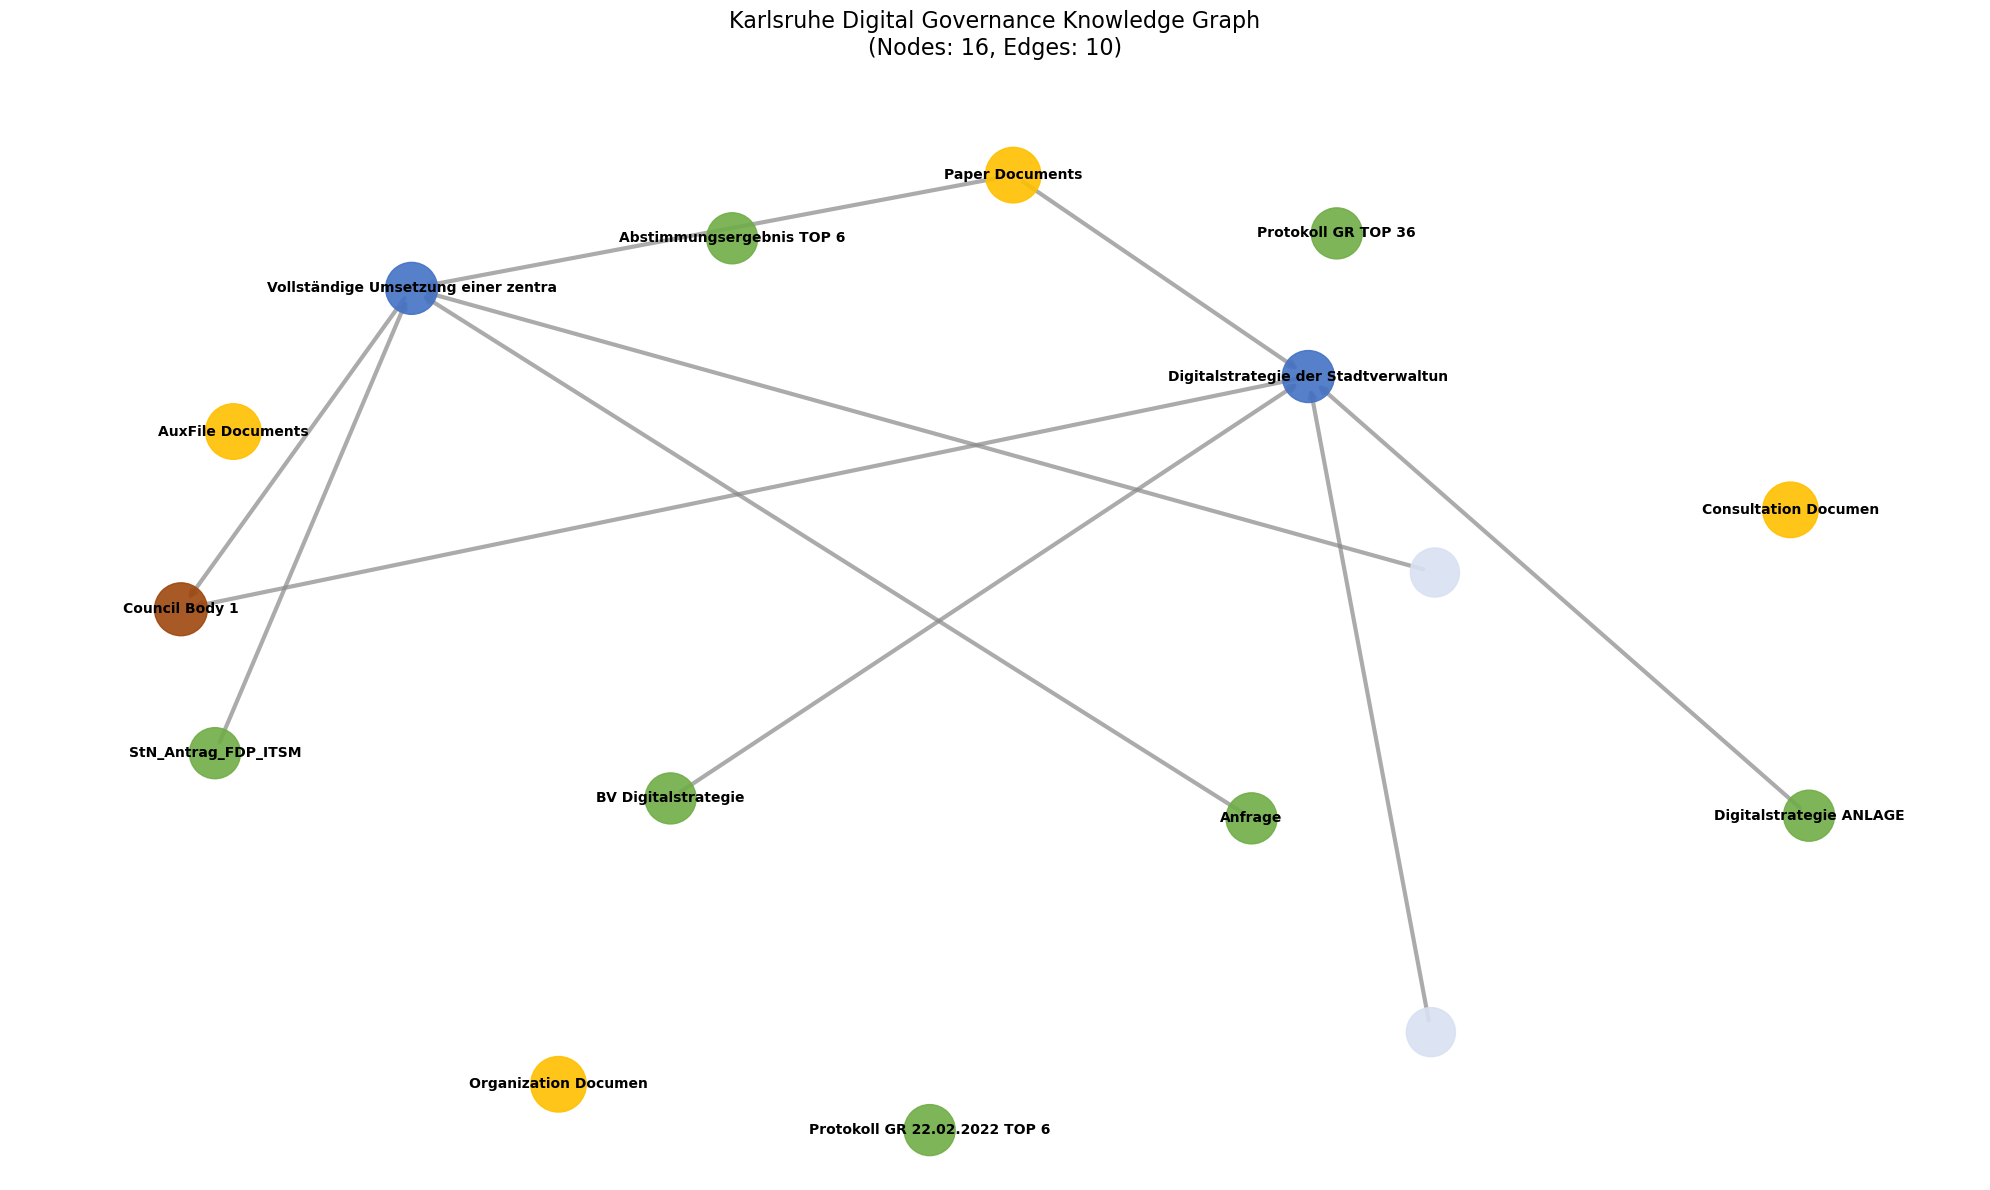

In [79]:
# ============================================
# SECTION 5: Create Visualization
# ============================================

fig = plt.figure(figsize=(20, 12))
pos = nx.spring_layout(G, k=3, iterations=100, seed=42)

# Prepare color, size, and label arrays
color_map = []
size_map = []
label_map = {}

for node in G.nodes():
    attrs = G.nodes[node]
    node_type = attrs.get('node_type', 'unknown')
    
    # Define size and color by type
    if node_type == 'Paper':
        color_map.append('#4472C4')
        size_map.append(1400)
        label_map[node] = attrs.get('name', str(node))[0:35]
    elif node_type == 'File':
        color_map.append('#70AD47')
        size_map.append(1350)
        label_map[node] = attrs.get('name', str(node))[0:30]
    elif node_type == 'Body':
        color_map.append('#9E480E')
        size_map.append(1450)
        label_map[node] = attrs.get('name', str(node))[0:30]
    elif node_type == 'TimelineEvent':
        color_map.append('#D9E1F2')
        size_map.append(1250)
        label_map[node] = ''
    elif node_type == 'category':
        color_map.append('#FFC000')
        size_map.append(1600)
        label_map[node] = attrs.get('name', str(node))[0:20]
    else:
        color_map.append('#CCCCCC')
        size_map.append(1200)
        label_map[node] = ''

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=size_map, alpha=0.9)

# Draw edges (thicker)
nx.draw_networkx_edges(G, pos, width=3, alpha=0.7, edge_color='#888888')

# Draw labels (ALL node types now have labels)
nx.draw_networkx_labels(G, pos, label_map, font_size=10, font_weight='bold')

plt.title(f'Karlsruhe Digital Governance Knowledge Graph\n(Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()})', fontsize=16, pad=20)
plt.axis('off')
plt.tight_layout()
plt.savefig('karlsruhe_governance_graph.png', dpi=300, bbox_inches='tight')
plt.show()

In [80]:
# ============================================
# 6. Alternative: Interactive HTML Visualization
# ============================================

try:
    from pyvis import network
    from IPython.display import HTML
    from pathlib import Path
    # net = Network(notebook=True)
    
    # Create interactive network
    # cdn_resources = "in_line",
    net = network.Network(notebook=True, cdn_resources = "in_line", height='600px', width='100%', bgcolor='white', font_color='black')
    
    # Add nodes with colors
    for node, attrs in G.nodes(data=True):
        node_type = attrs.get('node_type', 'unknown')
        if node_type == 'Paper':
            color = '#4472C4'
        elif node_type == 'File':
            color = '#70AD47'
        elif node_type == 'Body':
            color = '#9E480E'
        elif node_type == 'TimelineEvent':
            color = '#D9E1F2'
        elif node_type == 'category':
            color = '#FFC000'
        else:
            color = '#CCCCCC'
        
        # Convert tuple node to string ID
        node_id = f"{node[0]}_{node[1]}"
        label = attrs.get('name', str(node))[0:40]
        title = f"Type: {node_type}\nDate: {attrs.get('date', 'N/A')}"
        
        net.add_node(
            node_id,
            label=label,
            group=node_type,
            color=color,
            size=25 if node_type != 'category' else 35,
            title=title
        )
    
    # Add edges
    for u, v, attrs in G.edges(data=True):
        u_id = f"{u[0]}_{u[1]}"
        v_id = f"{v[0]}_{v[1]}"
        rel = attrs.get('relation', '')
        weight = attrs.get('weight', 1)
        
        net.add_edge(
            u_id,
            v_id,
            label=rel,
            weight=weight
        )
    
    # Configure physics
    net.barnes_hut(gravity=-80000, central_gravity=3, spring_length=250)
    
    # Enable interaction options
    net.toggle_physics(True)
    net.show_buttons(filter_=['physics'])
    
    # Save and display
    net.save_graph(f'{figName}.html')
    print(f"✓ Interactive visualization saved as '{figName}.html'")
    #net.show(f"{figName}.html")
    # Read the HTML file content
    html_content = Path(f"{figName}.html").read_text()
    display(HTML(html_content))

    
except ImportError:
    print("⚠ PyVis not installed - skip interactive HTML export")
    print("  Install with: pip install pyvis")

✓ Interactive visualization saved as 'risualization.html'


In [81]:
# ============================================
# 7. Create DataFrame Export
# ============================================

# Export node data for external analysis
node_df = pd.DataFrame([
    {
        'node_id': f"{node[0]}_{node[1]}",
        'node_type': attrs['node_type'],
        'name': attrs.get('name', ''),
        'date': attrs.get('date', ''),
        'reference': attrs.get('reference', ''),
        'file_name': attrs.get('file_name', '')
    }
    for node, attrs in G.nodes(data=True)
])

node_df.to_csv('karlsruhe_nodes.csv', index=False)
print("✓ Node data exported to 'karlsruhe_nodes.csv'")

# Export edge data
edge_df = pd.DataFrame([
    {
        'source': f"{u[0]}_{u[1]}",
        'target': f"{v[0]}_{v[1]}",
        'relation': attrs.get('relation', ''),
        'weight': attrs.get('weight', 1)
    }
    for u, v, attrs in G.edges(data=True)
])

edge_df.to_csv('karlsruhe_edges.csv', index=False)
print("✓ Edge data exported to 'karlsruhe_edges.csv'")

✓ Node data exported to 'karlsruhe_nodes.csv'
✓ Edge data exported to 'karlsruhe_edges.csv'


In [82]:
# ============================================
# 8. Key Insights Summary
# ============================================

print(f"\n{'='*60}")
print("KEY INSIGHTS")
print('='*60)

# Find papers with most attachments
paper_attachments = defaultdict(int)
for u, v, attrs in G.edges(data=True):
    if attrs.get('relation') == 'attached_to':
        if u[0] == 'File':
            paper_attachments[v[1]] += 1

print("\n📄 Papers with Most Document Attachments:")
for paper_id, count in sorted(paper_attachments.items(), key=lambda x: x[1], reverse=True)[:3]:
    attrs = G.nodes[('Paper', paper_id)]
    print(f"  • {attrs.get('name', 'Unknown')[:50]}: {count} attachments")

# Find timeline periods
timeline_periods = len(data.get('timeline', []))
print(f"\n📅 Timeline spans {timeline_periods} distinct periods")

# Event type distribution
print(f"\n📊 Event Type Distribution:")
for event_type, count in data['stats']['event_types'].items():
    pct = count / data['stats']['total_events'] * 100
    print(f"  • {event_type}: {count} ({pct:.1f}%)")

print("\n✅ Knowledge graph construction complete!")
print("   Files generated: karlsruhe_governance_graph.png, karlsruhe_governance_interactive.html")
print("                  karlsruhe_nodes.csv, karlsruhe_edges.csv")


KEY INSIGHTS

📄 Papers with Most Document Attachments:
  • Digitalstrategie der Stadtverwaltung Karlsruhe: 2 attachments
  • Vollständige Umsetzung einer zentralen städtischen: 2 attachments

📅 Timeline spans 4 distinct periods

📊 Event Type Distribution:
  • Paper: 5 (41.7%)
  • Consultation: 2 (16.7%)
  • Organization: 3 (25.0%)
  • AuxFile: 7 (58.3%)

✅ Knowledge graph construction complete!
   Files generated: karlsruhe_governance_graph.png, karlsruhe_governance_interactive.html
                  karlsruhe_nodes.csv, karlsruhe_edges.csv
